# Imports

In [1]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
import matplotlib.pyplot as plt

# Setup

In [2]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'


##### read into df...
df = pd.read_csv(clean_path)

##### drop analyses >5% analytical error...
df['percent'] = df['error'] / df['age'] * 100
mask = df['percent'] < 5
df = df.loc[mask]
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)
df.head()

,index,sample,zone,mnz,texture,texture_chem,n,age,error,CaO,...,Dy2O3,Ho2O3,Er2O3,Tm2O3,Yb2O3,SO3,PbO,lree,HREE,percent
0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.701308,0.995224,...,0.181849,0.021200,0.034744,0.069987,0.009827,0.019002,0.097798,60.335048,1.371961,0.201034
1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.794103,1.435283,...,0.010042,0.010042,0.010042,0.020180,0.010042,0.018376,0.134090,58.128568,0.677921,0.258548
2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.800000,0.827626,...,0.125878,0.009912,0.014868,0.009912,0.009912,0.020815,0.080285,62.602214,1.604702,0.224719
3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.381304,0.852869,...,0.062720,0.009927,0.009927,0.009927,0.009927,0.016638,0.084487,62.652220,1.401806,0.462438
4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.461027,0.984389,...,0.079168,0.009819,0.009819,0.061324,0.009819,0.015049,0.087027,61.816443,1.415405,0.413607


# Gaussian Mixture Model

## Determine number of Components

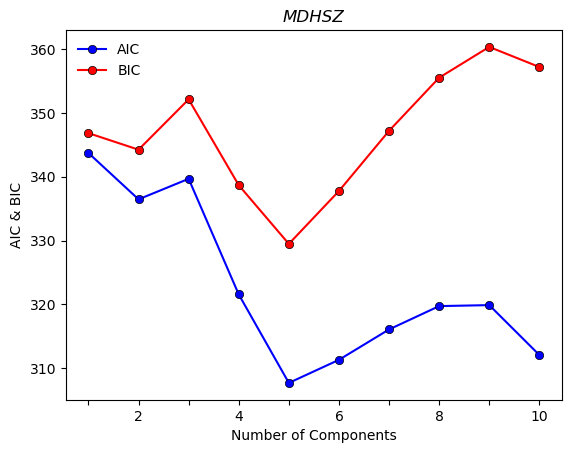

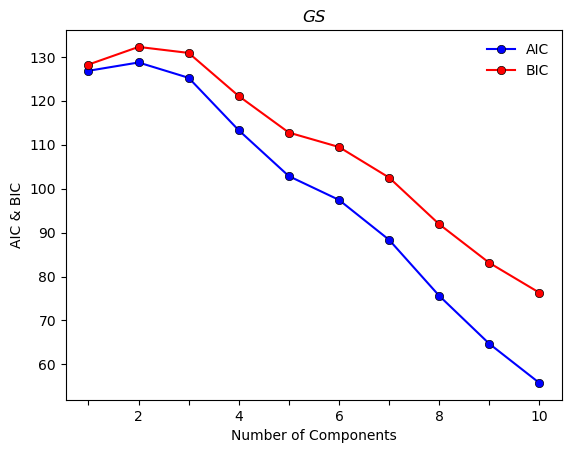

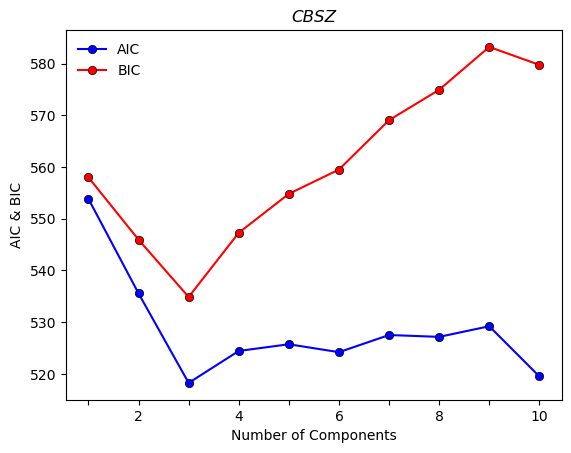

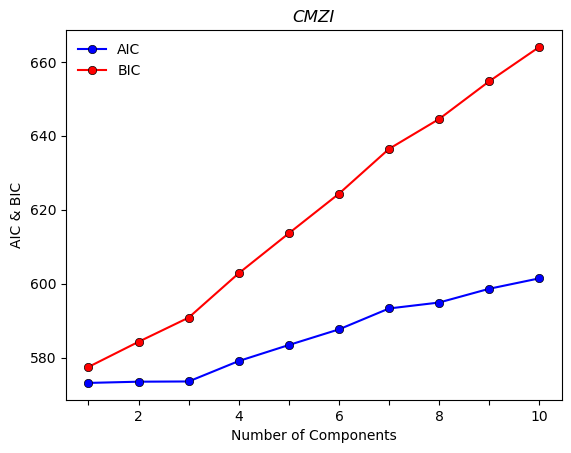

In [3]:


for zone in ['MDHSZ', 'GS', 'CBSZ', 'CMZI']:

    df_subset = df[df['zone']==zone].copy()
    ages = df_subset['age'].to_numpy().reshape(-1,1)

    aic = []
    bic = []
    
    for k in np.arange(1, 11, 1):

        gm = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=111).fit(ages)
        aic.append(gm.aic(ages))
        bic.append(gm.bic(ages))
    
    fig, ax = plt.subplots()
    ax.plot(np.arange(1, 11, 1), aic, color='blue', marker='o', markeredgecolor='k', markeredgewidth=0.5, label='AIC')
    # ax2 = ax.twinx()
    ax.plot(np.arange(1, 11, 1), bic, color='red', marker='o', markeredgecolor='k', markeredgewidth=0.5, label='BIC')

    ax.legend(loc='best', frameon=False)
    ax.set_xticks(np.arange(1,11,1))
    ax.set_xticklabels(str(i) if i%2==0 else '' for i in np.arange(1,11,1))
    ax.set_xlabel('Number of Components')
    ax.set_ylabel('AIC & BIC')
    ax.set_title(zone, style='italic')




## Final Cluster Labels

In [4]:
from scipy.stats import t

def cluster_stats(ages, se, two_sigma=False):
    # ages = np.asarray(ages, float)
    # se   = np.asarray(se, float)
    n    = len(ages)
    w    = 1.0 / (se**2)

    # Weighted mean
    mu = np.sum(w * ages) / np.sum(w)

    # MSWD (χ²/(n-1))
    chi2 = np.sum(w * (ages - mu)**2)
    mswd = chi2 / max(n - 1, 1)

    # Uncertainty on the mean (inflate if MSWD>1)
    sigma_mu = np.sqrt(1.0 / np.sum(w))
    sigma_mu_adj = sigma_mu * np.sqrt(mswd) if mswd > 1 else sigma_mu

    # 95% CI (or 2σ if you prefer)
    if two_sigma:
        half_width = 2.0 * sigma_mu_adj
    else:
        tcrit = t.ppf(0.975, df=max(n - 1, 1))
        half_width = tcrit * sigma_mu_adj

    return {
        "mean": mu,
        "mswd": mswd,
        "n": n,
        "sigma_mean": sigma_mu_adj,
        "ci95_halfwidth": half_width
    }


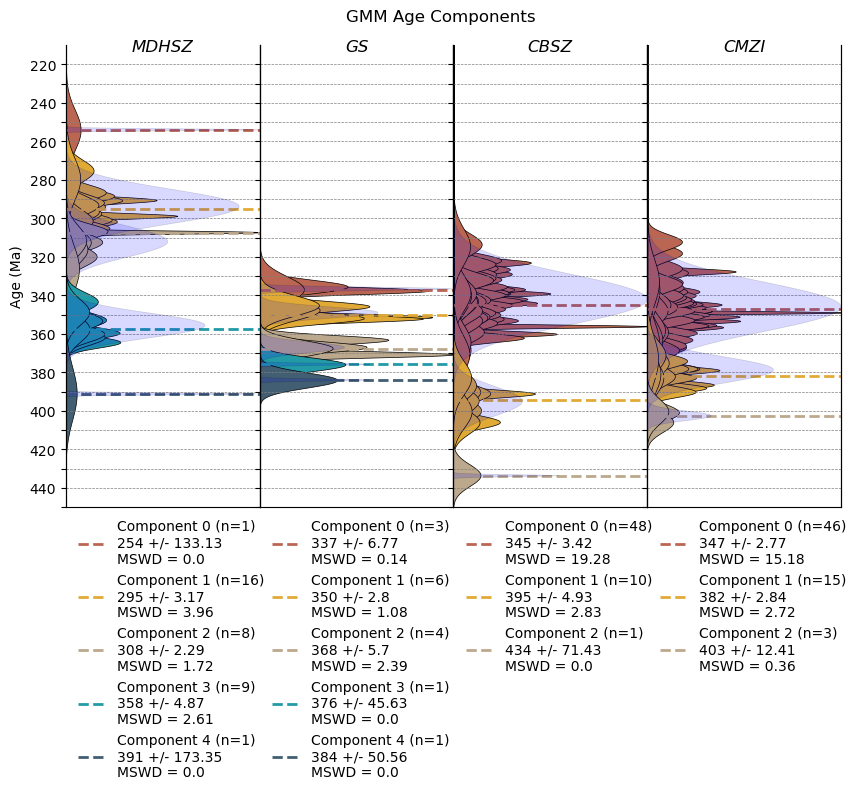

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=4, sharey=True, figsize=(10,6))
plt.subplots_adjust(wspace=0)

# define number of components from above
zone_clusters = {'MDHSZ': 5, 
                 'GS': 5, 
                 'CBSZ': 3, 
                 'CMZI': 3}

# define colors for plots
k_colors = ['#BB6653', '#E1AA36', '#BCA88D', '#239BA7', '#415E72', '#3E3F29']

# initialize dictionary to hold weighted mean stats
all_stats = {}

# create timeline array
timeline = np.linspace(200, 500, 1000)

##### iterate through structural zones...
for idx, zone in enumerate(zone_clusters.keys()):

    # initialize zone entry in dictionary
    all_stats[zone] = {}

    # create subset df for zone of interest
    df_subset = df[df['zone']==zone].copy()

    # get array of ages and errors for GMM model (shape: N x 1)
    all_ages = df_subset['age'].to_numpy().reshape(-1,1)
    all_errors = df_subset['error'].to_numpy().reshape(-1,1)

    # fit GMM using chosen components
    gm = GaussianMixture(n_components=zone_clusters[zone], covariance_type="full", n_init=10, random_state=111).fit(all_ages)

    # extract GMM stats...
    means = gm.means_.ravel()                   # component means
    stds  = np.sqrt(gm.covariances_).ravel()    # component standard deviations
    weights = gm.weights_.ravel()               # component weights
    
    # order stats by component mean age (young→old) for consistent colors
    order = np.argsort(means)
    means, stds, weights = means[order], stds[order], weights[order]

    # get component PDFs...
    components = []
    stds_plot = np.clip(stds, 0.5, None)
    for mu, sd, w in zip(means, stds_plot, weights):
        components.append(w * norm.pdf(timeline, loc=mu, scale=sd))

    # responsibilities and labels, remapped to the ordered component index
    R = gm.predict_proba(all_ages)[:, order]
    labels = R.argmax(axis=1)
    df_subset['labels'] = labels

    df_subset.sort_values(['labels', 'error'], inplace=True)
    df_subset.reset_index(drop=True, inplace=True)

    # keep track of maximum density to set xlim in plots...
    density_max = 0.0
    ax2_density_max = 0.0

    # plot component PDFs...
    ax2 = ax[idx].twiny()
    for j, density in enumerate(components):
        ax2_density_max = max(ax2_density_max, density.max())
        ax2.fill_between(density, timeline, color='blue', linewidth=0.5, edgecolor='k', alpha=0.15, zorder=2)


    ##### iterate through components...
    for k in df_subset['labels'].unique():
        
        # get ages, errors, & weighted mean stats for component of interest...
        ages = df_subset.loc[df_subset['labels'] == k, 'age'].to_numpy().reshape(-1,1)
        errors = df_subset.loc[df_subset['labels'] == k, 'error'].to_numpy().reshape(-1,1)
        stats = cluster_stats(ages, errors, two_sigma=False)
        all_stats[zone][k] = stats
        

        ##### plot individual sample gaussian curves...
        for _, row in df_subset[df_subset['labels'] == k].iterrows():
            mean = row['age']
            error = row['error']
            k_label = row['labels']

            # get age range for calculating sample PDF
            age_range = np.linspace(mean - 4 * error, mean + 4 * error, 1000)

            # get density of PDF for sample
            density = norm.pdf(age_range, mean, error)

            # update density max with highest value (or keep old value)
            density_max = max(density_max, density.max())

            # plot PDF curves
            ax[idx].fill_between(density, age_range, alpha=1, color=k_colors[k_label], linewidth=0.5, edgecolor='k')
        
        # construct label with weighted mean stats
        label = f"Component {k} (n={int(stats['n'])})\n{round(stats['mean'])} +/- {round(stats['ci95_halfwidth'], 2)}\nMSWD = {round(stats['mswd'],2)}"

        # plot weighted mean line
        ax[idx].axhline(y=stats['mean'], xmin=0, xmax=1, color=k_colors[k], linewidth=2, linestyle='--', zorder=2, label=label)

        # plot CI ribbon around mean (if at least 3 samples)...
        # if stats['n'] >= 3:
        #     ax[idx].fill_between(x=np.linspace(0,2,100), y1=stats['mean'] - stats['ci95_halfwidth'], y2=stats['mean'] + stats['ci95_halfwidth'], color=k_colors[k_label], alpha=0.5, zorder=0.5)
    ax[idx].legend(loc='upper left', bbox_to_anchor=(0,0), frameon=False)

        

    ax2.set_xticks([])
    ax2.set_xlim(0, ax2_density_max)
    ax2.spines['top'].set_visible(False)

    ax[idx].set_title(zone, style='italic', y=0.97)
    ax[idx].set_xlim(0, density_max)

    ax[idx].invert_yaxis()
    ax2.invert_yaxis()


##### figure styling...
for axes in ax:
    # axes.set_xlim(0)
    axes.set_ylim(210, 450)
    axes.grid(visible=True, axis='y', linestyle='--', color='gray', linewidth=0.5)
    axes.set_xticks([])
    axes.spines['top'].set_visible(False)
    axes.spines['bottom'].set_visible(False)

ax[0].set_yticks(np.arange(220, 451, 10))
ax[0].set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax[0].set_ylabel('Age (Ma)')

plt.gca().invert_yaxis()
plt.suptitle('GMM Age Components', y=0.94)
# plt.savefig(r'../results/kmeans.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

In [67]:
x = df.loc[df['zone']=='CBSZ'].copy()
ages = x['age'].to_numpy().reshape(-1,1)

gm = GaussianMixture(n_components=3, covariance_type='full').fit(ages)

# extract GMM stats...
means = gm.means_.ravel()                   # component means
stds  = np.sqrt(gm.covariances_).ravel()    # component standard deviations
weights = gm.weights_.ravel()               # component weights

# order stats by component mean age (young→old) for consistent colors
order = np.argsort(means)
means, stds, weights = means[order], stds[order], weights[order]

# get component PDFs...
components = []
for mu, sd, w in zip(means, stds, weights):
    components.append(w * norm.pdf(timeline, loc=mu, scale=sd))

# responsibilities and labels, remapped to the ordered component index
R = gm.predict_proba(ages)[:, order]
labels = R.argmax(axis=1)
x['labels'] = labels

x.sort_values(['labels', 'error'], inplace=True)
x.reset_index(drop=True, inplace=True)

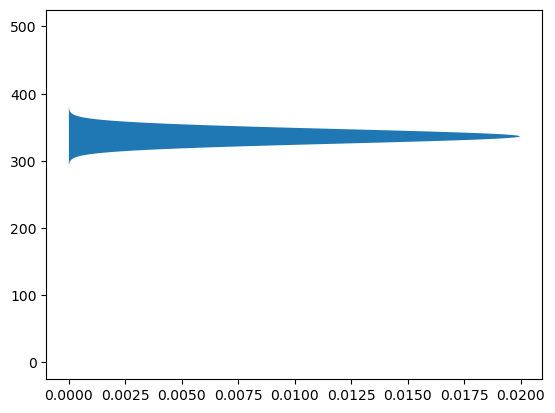

In [69]:
plt.fill_between(components[0], np.linspace(200,500,1000))

In [64]:
x

,index,sample,zone,mnz,texture,texture_chem,n,age,error,CaO,...,Dy2O3,Ho2O3,Er2O3,Tm2O3,Yb2O3,SO3,PbO,lree,HREE,percent
2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.000000,0.800000,0.827626,...,0.125878,0.009912,0.014868,0.009912,0.009912,0.020815,0.080285,62.602214,1.604702,0.224719
6,145,P14-005A-5B,CBSZ,m11,core,Y depleted core,NaN,360.000000,1.500000,0.697796,...,0.057003,0.009828,0.009828,0.009828,0.009828,0.012777,0.081573,62.870397,1.246204,0.416667
9,171,P14-005A-5B,CBSZ,m11,rim,Y enriched rim,NaN,339.000000,1.600000,0.876585,...,0.286498,0.010053,0.010053,0.010053,0.010053,0.024126,0.081426,61.511706,2.039667,0.471976
15,40,9-1-L,CBSZ,m24,overgrowth,Y depleted overgrowth,5.0,343.940000,1.852458,0.800298,...,0.070070,0.009808,0.009808,0.112897,0.009808,0.019250,0.077374,62.614760,1.473757,0.538599
18,174,P14-005A-5B,CBSZ,m18,core,Y enriched core,NaN,391.000000,1.900000,0.831977,...,0.327597,0.024969,0.010986,0.009988,0.009988,0.023971,0.096881,61.466396,2.151354,0.485934
20,62,9-1-L,CBSZ,m18,rim,Y enriched rim,6.0,322.966667,2.000444,1.021131,...,0.490873,0.009963,0.047473,0.071583,0.009963,0.010970,0.091470,59.309989,2.700528,0.619397
22,59,219-3-L,CBSZ,m40,overgrowth,Y depleted overgrowth,6.0,341.866667,2.095021,1.043406,...,0.217731,0.009967,0.037718,0.074307,0.009967,0.015779,0.102092,60.334697,1.373563,0.612818
26,69,9-1-L,CBSZ,m9,overgrowth,Y depleted overgrowth,5.0,336.800000,2.161712,0.858987,...,0.126999,0.009945,0.021743,0.009945,0.009945,0.010105,0.089640,61.478005,1.430798,0.641839
27,148,P14-005A-5B,CBSZ,m4,core,Y depleted core,NaN,362.000000,2.200000,0.727380,...,0.047309,0.009856,0.009856,0.009856,0.009856,0.026611,0.091662,62.248177,1.111768,0.607735
29,56,219-3-L,CBSZ,m9,overgrowth,Y depleted overgrowth,6.0,342.616667,2.261919,0.727993,...,0.337831,0.009972,0.022144,0.045640,0.009972,0.023285,0.068622,61.892560,2.277347,0.660189
